# Semantic matching: embeddings and clustering of real Hebrew product names

A first exploration notebook for the matching pipeline (`docs/matching.md`, steps A to D). It takes
**real** supermarket items from the committed transparency-file fixtures, normalizes them with the
catalog's own code, embeds the names, looks at nearest neighbours, clusters the items inside the
blocks the catalog uses, and then asks the question the project cares about: **how many of the
pairs the clusters put together are wrong in a way that costs trust** (3% milk next to 1% milk)?

Nothing here reimplements ingestion or normalization: items come from the chains' adapters
(`smartcart_ingest.adapters`, through `smartcart_catalog.review_packet.load_real_items`), names and
sizes from `smartcart_catalog.normalize`, attributes from the rule extractor, embeddings from
`smartcart_catalog.embed`. No network and no database are needed for the default run.

**How to run** (from the repository root):

```
uv sync --group notebooks
uv run jupyter lab services/catalog/notebooks/semantic_matching.ipynb
# real sentence models (needs network to Hugging Face): add the catalog's embed extra
uv sync --all-packages --group notebooks --extra embed
SMARTCART_NB_EMBEDDER=bge-m3 uv run jupyter lab ...
```

Environment switches: `SMARTCART_NB_EMBEDDER` (`hash` default, `bge-m3`, `e5`),
`SMARTCART_NB_SAMPLE` (use a seeded sample of N real items and N gold items; 0 means all) and
`SMARTCART_NB_THRESHOLD` (cosine-distance threshold of the agglomerative clustering; unset means the
notebook picks it).

**Labels follow `docs/README.md`.** *Measured* means a number printed by a cell of this notebook on
the stated data. *Estimate* is a judgement. The real items are two small snapshots (200 rows per
chain per file, seven chains), the gold set is **synthetic**, and the "silver" labels are a machine
audit: none of this is evidence of precision on the real catalog, it is a way to see how an embedder
behaves.

In [1]:
import html
import json
import os
import random
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass
from itertools import combinations
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

T_START = time.perf_counter()
EMBEDDER = os.environ.get("SMARTCART_NB_EMBEDDER", "hash").strip().lower()
SAMPLE = int(os.environ.get("SMARTCART_NB_SAMPLE", "0") or 0)
THRESHOLD_OVERRIDE = os.environ.get("SMARTCART_NB_THRESHOLD", "").strip()
SEED = 20261028
RESULTS: dict[str, Any] = {}
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})


class Table:
    """Rows as an HTML table in Jupyter (each cell `dir=auto`, so Hebrew reads right to left and
    prices and numbers stay left to right) and as plain aligned text anywhere else."""

    def __init__(self, headers, rows):
        self.headers = [str(h) for h in headers]
        self.rows = [["" if c is None else str(c) for c in r] for r in rows]

    def _repr_html_(self):
        head = "".join(f"<th>{html.escape(h)}</th>" for h in self.headers)
        body = "".join(
            "<tr>"
            + "".join(
                f'<td dir="auto" style="text-align:start">{html.escape(c).replace(chr(10), "<br>")}</td>'
                for c in r
            )
            + "</tr>"
            for r in self.rows
        )
        return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"

    def __repr__(self):
        cells = [self.headers, *[[c.replace("\n", " / ") for c in r] for r in self.rows]]
        widths = [max(len(r[k]) for r in cells) for k in range(len(self.headers))]
        lines = ["  ".join(c.ljust(w) for c, w in zip(r, widths, strict=True)) for r in cells]
        return "\n".join([lines[0], "  ".join("-" * w for w in widths), *lines[1:]])


def n_pairs(k):
    return k * (k - 1) // 2


def pct(x, digits=1):
    return "n/a" if x is None else f"{100 * x:.{digits}f}%"


def ratio(a, b):
    return None if not b else a / b


def fmt(x, digits=3):
    return "n/a" if x is None else f"{x:.{digits}f}"

## a. Load real items

`load_real_items` runs each chain's own adapter over the committed **PriceFull** fixtures: the
audit snapshot `data/audit/real-2026-10-08/<chain>/real` and the ingest fixtures
`services/ingest/tests/fixtures/<chain>/real` (a later day, partly other stores of the same chains). No
network, no database. The two snapshots overlap (same item code, same chain) so they are merged by
item key, first occurrence wins.

A **valid barcode** is a GS1 GTIN (8, 12, 13 or 14 digits with a correct check digit), checked by
`smartcart_catalog.proposals.valid_barcode`. A chain-internal code is not a barcode. Items that share
a valid barcode across chains are the same product: that is the first ground truth used below.

In [2]:
from smartcart_catalog.normalize import is_truncated
from smartcart_catalog.proposals import valid_barcode
from smartcart_catalog.review_packet import (
    AUDIT_SNAPSHOT_DIR,
    FIXTURES_DIR,
    load_real_items,
)

SNAPSHOTS = {
    "audit snapshot": AUDIT_SNAPSHOT_DIR,
    "ingest fixtures": FIXTURES_DIR,
}
loaded = {label: load_real_items(path) for label, path in SNAPSHOTS.items()}
by_key = {}
for snapshot_items in loaded.values():
    for it in snapshot_items:
        by_key.setdefault(it.key, it)
all_items = list(by_key.values())

bc_chains = defaultdict(set)
for it in all_items:
    b = valid_barcode(it.barcode)
    if b:
        bc_chains[b].add(it.chain_id)
SHARED_BARCODES = {b for b, chains in bc_chains.items() if len(chains) > 1}


def subsample(items, n, keep=frozenset()):
    """A seeded sample of `n` items. Items whose key is in `keep` (the ones with a cross-chain
    barcode, which carry the ground truth) are taken first, up to half of the sample."""
    if not n or n >= len(items):
        return list(items)
    rnd = random.Random(SEED)
    kept = [it for it in items if it.key in keep][: n // 2]
    kept_keys = {it.key for it in kept}
    rest = [it for it in items if it.key not in kept_keys]
    rnd.shuffle(rest)
    take = {it.key for it in kept + rest[: n - len(kept)]}
    return [it for it in items if it.key in take]


items_used = subsample(
    all_items,
    SAMPLE,
    keep={it.key for it in all_items if valid_barcode(it.barcode) in SHARED_BARCODES},
)

rows_out = []
for chain in sorted({it.chain_name for it in all_items}):
    mine = [it for it in all_items if it.chain_name == chain]
    rows_out.append(
        [
            chain,
            *(sum(it.chain_name == chain for it in loaded[s]) for s in SNAPSHOTS),
            len(mine),
            sum(valid_barcode(it.barcode) is not None for it in mine),
            sum(valid_barcode(it.barcode) in SHARED_BARCODES for it in mine),
            sum(it.is_weighed for it in mine),
            sum(is_truncated(it.chain_id, it.raw_name) for it in mine),
        ]
    )
rows_out.append(
    [
        "total",
        *(len(loaded[s]) for s in SNAPSHOTS),
        len(all_items),
        *(sum(r[k] for r in rows_out) for k in range(4, 8)),
    ]
)
print(f"Real items merged by key: {len(all_items)}; used in this run: {len(items_used)}")
print(f"Barcodes sold by two or more chains (valid GS1): {len(SHARED_BARCODES)}")
Table(
    [
        "chain",
        "audit snapshot",
        "ingest fixtures",
        "merged",
        "valid GS1 barcode",
        "cross-chain barcode",
        "weighed",
        "name cut at chain width",
    ],
    rows_out,
)

Real items merged by key: 1710; used in this run: 1710
Barcodes sold by two or more chains (valid GS1): 54


chain,audit snapshot,ingest fixtures,merged,valid GS1 barcode,cross-chain barcode,weighed,name cut at chain width
אושר עד,200,200,224,214,3,28,184
טיב טעם,200,200,206,14,4,94,12
יוחננוף,200,200,276,128,45,88,154
קינג סטור,200,200,238,96,1,97,0
קרפור (מגה),200,200,268,239,5,11,233
רמי לוי,200,200,216,206,7,3,180
שופרסל,200,200,282,236,44,0,207
total,1400,1400,1710,1133,109,321,970


## b. Normalize names and sizes, extract attributes

`normalize` expands chain abbreviations ("1 ל'" becomes "1 ליטר"), unifies quotes, and reads the size
and pack count from the chain's fields or, failing that, from the name. The rule extractor then
reads the product type, fat percentage, state (fresh, frozen), flavor and plant base from the
cleaned name. Both are the production code paths (`smartcart-catalog normalize` and `extract`). Chain
names are often cut at a fixed width (the last column above), so a missing attribute usually means
"not stated", never "absent": the judge treats unknown as "send to review".

`prepare` bundles what the later sections need per item: the cleaned name (this is what gets
embedded), the department and base unit (the **block**, exactly as `block.py` defines it), and the
attribute values used to find critical conflicts.

In [3]:
from smartcart_catalog.block import block_prefix
from smartcart_catalog.extract.rule import RuleExtractor
from smartcart_catalog.models import Attributes, ExtractionError
from smartcart_catalog.normalize import normalize
from smartcart_catalog.proposals import UNTYPED_KEYS
from smartcart_catalog.seed import load_catalog

CATALOG = load_catalog()
EXTRACTOR = RuleExtractor(CATALOG)
ATTR_NAMES = ("product_type", "fat_pct", "state", "flavor", "base", "size")


@dataclass
class Row:
    n: int
    src: Any  # SourceItem
    norm: Any  # NormalizedItem
    attrs: Any  # Attributes
    barcode: str | None  # valid GS1 barcode, or None
    truncated: bool
    dept: str | None
    base_unit: str | None
    vals: tuple  # values of ATTR_NAMES; None means "not stated"
    crit: frozenset  # the attribute names that are critical for this item's product type

    @property
    def text(self):
        return self.norm.clean_name

    @property
    def block(self):
        return (self.dept or "?", self.base_unit or "?")


def prepare(items):
    """Normalize and extract, like `smartcart-catalog normalize` and `extract --extractor rule`."""
    norms = []
    for n, it in enumerate(items, start=1):
        record = {
            "id": n,
            "chain_id": it.chain_id,
            "chain_name": it.chain_name,
            "item_code": it.item_code,
            "barcode": it.barcode,
            "raw_name": it.raw_name,
            "manufacturer": it.manufacturer,
            "quantity": it.quantity,
            "unit": it.unit,
            "is_weighed": it.is_weighed,
        }
        norms.append(normalize(record, item_id=n))
    extracted = EXTRACTOR.extract(norms)
    rows = []
    for n, (it, nm, a) in enumerate(zip(items, norms, extracted, strict=True), start=1):
        if isinstance(a, ExtractionError):
            a = Attributes()
        size = nm.total_quantity if nm.base_unit in ("100g", "100ml", "unit") else None
        rule = CATALOG.rules.get(a.product_type)
        keys = rule.critical_keys if rule else UNTYPED_KEYS
        rows.append(
            Row(
                n=n,
                src=it,
                norm=nm,
                attrs=a,
                barcode=valid_barcode(it.barcode),
                truncated=is_truncated(it.chain_id, it.raw_name),
                dept=block_prefix(a.category_path),
                base_unit=nm.base_unit,
                vals=(a.product_type, a.fat_pct, a.state, a.flavor, a.base, size),
                crit=frozenset(keys),
            )
        )
    return rows


rows = prepare(items_used)
typed = sum(r.attrs.product_type is not None for r in rows)
sized = sum(r.norm.base_unit is not None for r in rows)
fat = sum(r.attrs.fat_pct is not None for r in rows)
print(
    f"{len(rows)} items: {typed} with a product type ({pct(typed / len(rows))}), "
    f"{sized} with a parsed size/base unit ({pct(sized / len(rows))}), "
    f"{fat} with a fat percentage ({pct(fat / len(rows))})"
)


def spread(pool, k, seed):
    """k rows from `pool`, one chain at a time, so the examples are not all from one chain."""
    rnd = random.Random(seed)
    by_chain = defaultdict(list)
    for r in pool:
        by_chain[r.src.chain_name].append(r)
    for lst in by_chain.values():
        rnd.shuffle(lst)
    out = []
    while len(out) < k and any(by_chain.values()):
        for chain in sorted(by_chain):
            if by_chain[chain] and len(out) < k:
                out.append(by_chain[chain].pop())
    return out


def describe(r):
    nm, a = r.norm, r.attrs
    size = "" if nm.total_quantity is None else f"{nm.total_quantity:g} {nm.unit} x{nm.pack_count}"
    return [
        r.src.chain_name,
        r.src.raw_name,
        nm.clean_name if nm.clean_name != r.src.raw_name else "(unchanged)",
        size,
        nm.base_unit,
        a.product_type,
        a.fat_pct,
        a.state,
        a.flavor,
        "cut" if r.truncated else "",
    ]


changed = [r for r in rows if r.norm.clean_name != r.src.raw_name]
rich = [
    r
    for r in rows
    if r.attrs.product_type and r.norm.total_quantity and r.norm.clean_name == r.src.raw_name
]
examples = spread(changed, 5, SEED) + spread(rich, 5, SEED + 1)
print("10 before/after examples: the first five show a changed name, the last five typed items")
Table(
    [
        "chain",
        "raw name",
        "clean name",
        "size",
        "base unit",
        "type",
        "fat %",
        "state",
        "flavor",
        "cut",
    ],
    [describe(r) for r in examples],
)

1710 items: 586 with a product type (34.3%), 1513 with a parsed size/base unit (88.5%), 35 with a fat percentage (2.0%)
10 before/after examples: the first five show a changed name, the last five typed items


chain,raw name,clean name,size,base unit,type,fat %,state,flavor,cut
אושר עד,אקונומיקה פסגה 4 ליט,אקונומיקה פסגה 4 ליטר,4000 ml x1,100ml,bleach,,,,cut
טיב טעם,"אבקת חלבון מי גבינה קומבט וניל 2.27 ק""ג",אבקת חלבון מי גבינה קומבט וניל 2.27 קילוגרם,2270 g x1,100g,,,,cheese,cut
יוחננוף,בולגרית בכר16%,בולגרית בכר16%,1000 g x1,kg,bulgarian_cheese,16,,,
קינג סטור,פירורי לחם מזוהבים 800 ג' אלחסן,פירורי לחם מזוהבים 800 גרם אלחסן,800 g x1,100g,breadcrumbs,,,,
קרפור (מגה),"ישן נושן 750מ""ל.",ישן נושן 750מיליליטר.,750 ml x1,100ml,,,,,
אושר עד,מיונז תלמה 500 גרם,(unchanged),500 g x1,100g,mayonnaise,,,,
טיב טעם,בורקס - מצבע סוף יום,(unchanged),1000 g x1,kg,burekas,,,,
יוחננוף,חלה רגילה 500 גרם,(unchanged),500 g x1,100g,challah,,,,
קינג סטור,תירס ארוז,(unchanged),1000 g x1,kg,sweet_corn,,canned,,
קרפור (מגה),תירס מהשדה יכין 400,(unchanged),400 g x1,100g,sweet_corn,,,,cut


## c. Embeddings

The `EMBEDDER` switch picks the vector space:

| value | model | needs |
|---|---|---|
| `hash` (default) | the repo's `HashEmbedder`: signed feature hashing of character 2-4-grams and words of the normalized text. Offline and deterministic, **no semantics** (it knows that two strings share letters, not that they mean the same) | nothing |
| `bge-m3` | `BAAI/bge-m3` through the repo's `BgeM3Embedder`, the model the catalog decided on (`docs/architecture.md`, step C) | the `embed` extra and a download from huggingface.co |
| `e5` | `intfloat/multilingual-e5-base`, a smaller multilingual model (768 dimensions, with `query: ` and `passage: ` prefixes) | the `embed` extra and a download |

Models are loaded lazily, only when chosen. If a model cannot be loaded (extra not installed, no
route to huggingface.co) the notebook prints why and **continues with the hash embedder**, and every
result below carries the label of the embedder that was actually used.

In [4]:
from smartcart_catalog.embed import HashEmbedder, get_embedder

E5_MODEL = "intfloat/multilingual-e5-base"


class SentenceModelEmbedder:
    """Any sentence-transformers model, loaded on first use (the e5 family wants prefixes)."""

    def __init__(self, model_name, query_prefix="", passage_prefix=""):
        self.model_name = model_name
        self.query_prefix = query_prefix
        self.passage_prefix = passage_prefix
        self._model = None

    def _encode(self, texts, prefix):
        if self._model is None:
            from sentence_transformers import SentenceTransformer

            self._model = SentenceTransformer(self.model_name)
        vectors = self._model.encode(
            [prefix + t for t in texts],
            batch_size=32,
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=False,
        )
        return [[float(x) for x in v] for v in vectors]

    def embed(self, texts):
        return self._encode(texts, self.passage_prefix)

    def embed_queries(self, texts):
        return self._encode(texts, self.query_prefix)


def load_embedder(name):
    """(embedder, label, status). Never raises: a model that cannot be loaded is reported and the
    notebook goes on with the hash embedder."""
    if name == "hash":
        return HashEmbedder(), "hash", "offline, deterministic"
    # fail fast when huggingface.co is not reachable instead of retrying for minutes
    os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "10")
    os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
    try:
        if name in ("bge-m3", "bge_m3", "bgem3"):
            emb, label = get_embedder("bge-m3"), "bge-m3"
        elif name in ("e5", "multilingual-e5-base"):
            emb, label = SentenceModelEmbedder(E5_MODEL, "query: ", "passage: "), "e5"
        else:
            raise ValueError(f"unknown embedder {name!r}; use hash, bge-m3 or e5")
        emb.embed(["חלב 3%"])  # loads the weights now, so a failure is reported here
    except Exception as exc:  # noqa: BLE001 - any import, network or disk problem means "skip"
        reason = f"{type(exc).__name__}: {str(exc).splitlines()[0][:200] if str(exc) else ''}"
        print(f"SKIPPED embedder {name!r} ({reason}).")
        print(
            "Continuing with the hash embedder. To retry: uv sync --all-packages --group notebooks --extra embed, and reach huggingface.co."
        )
        return HashEmbedder(), "hash", f"fallback, {name} not available"
    return emb, label, "loaded"


embedder, EMB_LABEL, EMB_STATUS = load_embedder(EMBEDDER)
print(f"requested: {EMBEDDER}; used: {EMB_LABEL} ({embedder.model_name}); {EMB_STATUS}")


def embed_texts(texts, *, query=False):
    """Unit-length float64 vectors (one row per text); identical texts are embedded once."""
    uniq = list(dict.fromkeys(texts))
    fn = embedder.embed_queries if query and hasattr(embedder, "embed_queries") else embedder.embed
    vecs = np.asarray(fn(uniq), dtype=np.float64)
    vecs /= np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-12)
    index = {t: k for k, t in enumerate(uniq)}
    return vecs[[index[t] for t in texts]]


t0 = time.perf_counter()
X = embed_texts([r.text for r in rows])
print(f"embedded {len(rows)} names -> {X.shape} in {time.perf_counter() - t0:.1f} s")
rand = np.random.default_rng(SEED)
a_idx, b_idx = rand.integers(0, len(rows), 4000), rand.integers(0, len(rows), 4000)
keep = a_idx != b_idx
random_cos = np.sum(X[a_idx[keep]] * X[b_idx[keep]], axis=1)
print(
    "cosine of random item pairs: "
    f"median {np.median(random_cos):.3f}, 95th percentile {np.percentile(random_cos, 95):.3f}"
)

requested: hash; used: hash (hash-ngram-2-3-4-v1); offline, deterministic


embedded 1710 names -> (1710, 1024) in 0.5 s


cosine of random item pairs: median 0.043, 95th percentile 0.160


## d. Nearest neighbours

Ten shopper-style queries against the real items: top 5 by cosine similarity, with the product type
the rule extractor read from each hit. With `hash` the ranking is lexical (shared letters), so
"ביצים L" finds names with `L` and "ביצים", and a missing word is silently ignored. A semantic model
should also find a different word for the same thing.

The second table is the reason embeddings only generate candidates. It compares pairs that must
**not** be merged (3% vs 1% milk, fresh vs frozen salmon, soy vs almond drink) with pairs that are
the same product written differently. If the first group scores as high as the second, similarity
cannot tell them apart and the judge's hard rules have to.

In [5]:
QUERIES = [
    "חלב 3%",
    "קוטג'",
    "שמן זית",
    "נייר טואלט",
    "ביצים L",
    "פתיתים",
    "טחינה",
    "במבה",
    "גבינה צהובה",
    "אורז בסמטי",
]
QX = embed_texts(QUERIES, query=True)
nn_rows = []
for q, qv in zip(QUERIES, QX, strict=True):
    sims = X @ qv
    # items with the same chain and the same (often cut) name have the same vector: show them once
    seen = {}
    for k in np.argsort(-sims, kind="stable"):
        key = (rows[k].src.chain_id, rows[k].src.raw_name)
        if key in seen:
            seen[key][1] += 1
        elif len(seen) < 5:
            seen[key] = [k, 1]
        else:
            break
    for rank, (k, copies) in enumerate(seen.values(), start=1):
        r = rows[k]
        nn_rows.append(
            [
                q if rank == 1 else "",
                rank,
                f"{sims[k]:.3f}",
                r.src.chain_name,
                r.src.raw_name,
                copies if copies > 1 else "",
                r.attrs.product_type,
            ]
        )
print(f"embedder: {EMB_LABEL}")
Table(["query", "#", "cosine", "chain", "item", "same name x", "type read by rules"], nn_rows)

embedder: hash


query,#,cosine,chain,item,same name x,type read by rules
חלב 3%,1,0.606,רמי לוי,חלב תנובה 3% שומן 2,2,milk
,2,0.356,קרפור (מגה),פרוטאין מקס חטיף חלב,4,
,3,0.351,קרפור (מגה),רושה שוקולד חלב במיל,,chocolate_bar
,4,0.345,קרפור (מגה),משקה חלב נטול לקטוז,,milk_lactose_free
,5,0.343,קינג סטור,פסק זמן חלב מגדים 45 ג',,milk
קוטג',1,0.211,יוחננוף,סקוטש ברייט גליל ניי,,
,2,0.207,שופרסל,קורני חטיפי קוקוס שוק6יח,,
,3,0.194,שופרסל,קורני בייס קוקי&קרם138ג,,
,4,0.185,רמי לוי,קוטקס תחבושות לילה א,,
,5,0.176,קרפור (מגה),קונקורד קינג דויד 18,,


In [6]:
PAIR_TESTS = [
    ("חלב טרי 3% 1 ליטר", "חלב טרי 1% 1 ליטר", "must not merge: fat 3% vs 1%"),
    ("קוטג' 5% 250 גרם", "קוטג' 3% 250 גרם", "must not merge: fat 5% vs 3%"),
    ("סלמון טרי פילה", "סלמון קפוא פילה", "must not merge: fresh vs frozen"),
    ("משקה סויה 1 ליטר", "משקה שקדים 1 ליטר", "must not merge: soy vs almond"),
    ("יוגורט תות 150 גרם", "יוגורט וניל 150 גרם", "must not merge: flavor"),
    ("חלב טרי 3% 1 ליטר", "ח. טרי 3% 1 ליטר", "same product: abbreviation"),
    ("חלב 3% תנובה 1 ליטר", "חלב 3% שטראוס 1 ליטר", "same at any brand"),
    ("שמן זית כתית מעולה 750 מ״ל", "שמן זית 750 מל", "same product: wording"),
]
flat = [t for a, b, _ in PAIR_TESTS for t in (a, b)]
V = embed_texts(flat)
pair_rows = []
pair_sims = []
for k, (a, b, kind) in enumerate(PAIR_TESTS):
    sim = float(V[2 * k] @ V[2 * k + 1])
    pair_sims.append((kind, sim))
    pair_rows.append([kind, f"{sim:.3f}", a, b])
must_not = [s for kind, s in pair_sims if kind.startswith("must not")]
same = [s for kind, s in pair_sims if kind.startswith("same")]
RESULTS["must_not_merge_cosine_max"] = round(max(must_not), 3)
RESULTS["same_product_cosine_min"] = round(min(same), 3)
print(
    f"embedder: {EMB_LABEL}; highest cosine among must-not-merge pairs {max(must_not):.3f}, "
    f"lowest among same-product pairs {min(same):.3f}, "
    f"median of random item pairs {np.median(random_cos):.3f}"
)
Table(["kind", "cosine", "name A", "name B"], pair_rows)

embedder: hash; highest cosine among must-not-merge pairs 0.859, lowest among same-product pairs 0.644, median of random item pairs 0.043


kind,cosine,name A,name B
must not merge: fat 3% vs 1%,0.859,חלב טרי 3% 1 ליטר,חלב טרי 1% 1 ליטר
must not merge: fat 5% vs 3%,0.795,קוטג' 5% 250 גרם,קוטג' 3% 250 גרם
must not merge: fresh vs frozen,0.701,סלמון טרי פילה,סלמון קפוא פילה
must not merge: soy vs almond,0.718,משקה סויה 1 ליטר,משקה שקדים 1 ליטר
must not merge: flavor,0.768,יוגורט תות 150 גרם,יוגורט וניל 150 גרם
same product: abbreviation,0.843,חלב טרי 3% 1 ליטר,ח. טרי 3% 1 ליטר
same at any brand,0.705,חלב 3% תנובה 1 ליטר,חלב 3% שטראוס 1 ליטר
same product: wording,0.644,שמן זית כתית מעולה 750 מ״ל,שמן זית 750 מל


## e. Clustering inside blocks

The catalog never compares an item with everything: it **blocks** first. A block is the item's
department (first level of its taxonomy path, from the rule extractor) and its base unit (100 g,
100 ml, unit, kg), the same blocking `block.py` applies to canonicals. An item whose name states no
product type has no department and falls into the block "?" of its base unit, where clustering
relies on the embedding alone (most of the real items, see the table: 200-row price files are mostly
long-tail products the 245 canonicals do not cover).

Inside each block the notebook clusters with

* **agglomerative clustering**, average linkage on cosine distance, cut at a distance threshold;
* **HDBSCAN** (`sklearn.cluster.HDBSCAN`, `min_cluster_size=2`, leaf selection, noise points become
  singletons), which needs no threshold.

The threshold is chosen **without any ground truth**: the largest value of a grid for which at most
`CONFLICT_BUDGET` of the pairs inside clusters have a critical-attribute conflict according to the
rule extractor (definition below). That keeps the choice from peeking at the labels used in
section f. Override it with `SMARTCART_NB_THRESHOLD`.

**Critical conflict.** Two items in one cluster conflict when both state a value and the values
differ for the product type's critical keys (`data/product_type_rules.yaml`: fat percentage for
milk and cottage cheese, state for fish, flavor for cream cheese, plant base for plant drinks), or
when their product types differ. A difference in size is tracked separately: a different pack size
is a "close substitute", not a different product.

In [7]:
try:
    from sklearn.cluster import HDBSCAN
except ImportError:  # scikit-learn < 1.3
    HDBSCAN = None
print("HDBSCAN available:", HDBSCAN is not None)

CONFLICT_BUDGET = 0.03
GRID = [round(0.05 * k, 2) for k in range(2, 19)]


def pair_diffs(a, b):
    """(attributes that differ, the critical ones among them). Unknown values never conflict."""
    diffs = [
        name
        for name, x, y in zip(ATTR_NAMES, a.vals, b.vals, strict=True)
        if x is not None and y is not None and x != y
    ]
    crit = [d for d in diffs if d == "product_type" or (d in a.crit and d in b.crit)]
    return diffs, crit


def members_of(labels):
    groups = defaultdict(list)
    for i, lab in enumerate(labels):
        groups[lab].append(i)
    return groups


def cluster_stats(labels, rows_, with_attrs=True):
    groups = members_of(labels)
    sizes = [len(m) for m in groups.values()]
    st = {
        "clusters": len(groups),
        "singletons": sum(s == 1 for s in sizes),
        "largest": max(sizes),
        "pairs": sum(n_pairs(s) for s in sizes),
        "crit_pairs": 0,
        "soft_pairs": 0,
        "diff_by_attr": Counter(),
        "crit_by_attr": Counter(),
    }
    if with_attrs:
        for m in groups.values():
            for i, j in combinations(m, 2):
                diffs, crit = pair_diffs(rows_[i], rows_[j])
                if crit:
                    st["crit_pairs"] += 1
                elif diffs:
                    st["soft_pairs"] += 1
                st["diff_by_attr"].update(diffs)
                st["crit_by_attr"].update(crit)
    return st


def cluster(X_, rows_, method="agglomerative", threshold=0.5):
    """Cluster inside blocks; returns one integer label per row (unique across blocks)."""
    labels = np.zeros(len(rows_), dtype=int)
    next_id = 0
    blocks = defaultdict(list)
    for i, r in enumerate(rows_):
        blocks[r.block].append(i)
    for key in sorted(blocks):
        idx = blocks[key]
        if len(idx) == 1:
            labels[idx] = next_id
            next_id += 1
            continue
        Xb = X_[idx]
        if method == "agglomerative":
            lab = AgglomerativeClustering(
                n_clusters=None, metric="cosine", linkage="average", distance_threshold=threshold
            ).fit_predict(Xb)
        else:
            dist = np.clip(1.0 - Xb @ Xb.T, 0.0, 2.0)
            np.fill_diagonal(dist, 0.0)
            lab = HDBSCAN(
                min_cluster_size=2,
                min_samples=1,
                metric="precomputed",
                cluster_selection_method="leaf",
                copy=True,
            ).fit_predict(dist)
            noise = lab < 0
            lab = lab.copy()
            lab[noise] = lab.max() + 1 + np.arange(noise.sum())
        labels[idx] = lab + next_id
        next_id += int(lab.max()) + 1
    return labels


blocks = Counter(r.block for r in rows)
print(f"{len(blocks)} blocks; the 10 largest:")
Table(
    ["department", "base unit", "items"],
    [[d, u, n] for (d, u), n in blocks.most_common(10)],
)

HDBSCAN available: True
57 blocks; the 10 largest:


department,base unit,items
?,100g,384
?,unit,236
?,100ml,207
?,kg,184
?,?,126
pantry,100g,73
snacks,100g,55
produce,kg,47
dairy,100g,36
produce,100g,31


In [8]:
sweep = []
for thr in GRID:
    lab = cluster(X, rows, "agglomerative", thr)
    st = cluster_stats(lab, rows)
    sweep.append((thr, st))
ok = []
for thr, st in sweep:  # ascending: stop at the first threshold that breaks the budget
    if st["pairs"] and st["crit_pairs"] / st["pairs"] > CONFLICT_BUDGET:
        break
    ok.append(thr)
THRESHOLD = float(THRESHOLD_OVERRIDE) if THRESHOLD_OVERRIDE else (max(ok) if ok else GRID[0])
how = (
    "override"
    if THRESHOLD_OVERRIDE
    else f"largest within {pct(CONFLICT_BUDGET, 0)} critical-conflict pairs"
)
print(f"embedder {EMB_LABEL}: chosen distance threshold {THRESHOLD} ({how})")
Table(
    [
        "distance threshold",
        "clusters",
        "singletons",
        "largest",
        "pairs in clusters",
        "critical-conflict pairs",
        "size/soft-only pairs",
    ],
    [
        [
            f"{thr:.2f}" + (" <-" if thr == THRESHOLD else ""),
            st["clusters"],
            st["singletons"],
            st["largest"],
            st["pairs"],
            f"{st['crit_pairs']} ({pct(ratio(st['crit_pairs'], st['pairs']))})",
            f"{st['soft_pairs']} ({pct(ratio(st['soft_pairs'], st['pairs']))})",
        ]
        for thr, st in sweep
    ],
)

embedder hash: chosen distance threshold 0.25 (largest within 3% critical-conflict pairs)


distance threshold,clusters,singletons,largest,pairs in clusters,critical-conflict pairs,size/soft-only pairs
0.10,1603,1525,7,155,1 (0.6%),11 (7.1%)
0.15,1557,1447,7,226,3 (1.3%),22 (9.7%)
0.20,1504,1354,7,313,3 (1.0%),36 (11.5%)
0.25 <-,1449,1262,7,399,10 (2.5%),55 (13.8%)
0.30,1386,1161,8,504,26 (5.2%),70 (13.9%)
0.35,1315,1059,10,667,33 (4.9%),115 (17.2%)
0.40,1242,953,11,829,41 (4.9%),197 (23.8%)
0.45,1168,854,12,1022,49 (4.8%),261 (25.5%)
0.50,1079,748,12,1300,61 (4.7%),352 (27.1%)
0.55,995,669,18,1852,98 (5.3%),592 (32.0%)


In [9]:
LABELS = {"agglomerative": cluster(X, rows, "agglomerative", THRESHOLD)}
if HDBSCAN is not None:
    LABELS["hdbscan"] = cluster(X, rows, "hdbscan")

size_bins = [(1, 1), (2, 2), (3, 3), (4, 5), (6, 10), (11, 10**6)]


def bin_name(lo, hi):
    return (
        "1 (singleton)"
        if lo == hi == 1
        else str(lo)
        if lo == hi
        else f"{lo}-{hi}"
        if hi < 10**6
        else f"{lo}+"
    )


size_rows = []
for lo, hi in size_bins:
    size_rows.append(
        [bin_name(lo, hi)]
        + [sum(lo <= len(m) <= hi for m in members_of(lab).values()) for lab in LABELS.values()]
    )
print(f"cluster sizes (number of clusters per size), embedder {EMB_LABEL}, {len(rows)} items")
Table(["cluster size", *LABELS], size_rows)

cluster sizes (number of clusters per size), embedder hash, 1710 items


cluster size,agglomerative,hdbscan
1 (singleton),1262,514
2,144,237
3,31,109
4-5,6,68
6-10,6,15
11+,0,0


In [10]:
def show_cluster(lab, cid, members):
    names = [f"{rows[i].src.chain_name}: {rows[i].src.raw_name}" for i in members[cid]]
    return [cid, len(names), "/".join(rows[members[cid][0]].block), "\n".join(names)]


agg = LABELS["agglomerative"]
members = members_of(agg)
multi = sorted((c for c, m in members.items() if len(m) >= 2), key=lambda c: (-len(members[c]), c))
rnd = random.Random(SEED)
picked = multi[:5] + rnd.sample(multi[5:], min(5, len(multi[5:])))
print("10 example clusters (agglomerative): the 5 largest, then 5 drawn at random")
Table(["cluster", "size", "block", "members"], [show_cluster(agg, c, members) for c in picked])

10 example clusters (agglomerative): the 5 largest, then 5 drawn at random


cluster,size,block,members
110,7,?/100g,רמי לוי: אוכמניות 125 גרםרמי לוי: אוכמניות 125 גרםרמי לוי: אוכמניות 125 גרםרמי לוי: אוכמניות 125 גרםרמי לוי: אוכמניות 125 גרםשופרסל: מארז אוכמניות 125 גרםשופרסל: אוכמניות ארוז 125 גרם
329,7,?/100ml,"טיב טעם: מי קוקוס 330 מ""לטיב טעם: מי קוקוס פוקו בתוספת רימון 330 מ""לטיב טעם: מי קוקוס בתוספת גויאבה 330 מ""לטיב טעם: מי קוקוס בתוספת אננס 330 מ""לטיב טעם: מי קוקוס בתוספת ליצי 330 מ""לשופרסל: מי קוקוס 330 מ""לשופרסל: מי קוקוס + אננס 330 מ""ל"
343,7,?/100ml,"קינג סטור: רוטב טבסקו אדום 60 מ""לשופרסל: רוטב טבסקו 60 מ""לשופרסל: רוטב טבסקו ירוק 60 מ""לטיב טעם: רוטב טבסקו ציפוטלי 60 מ""לטיב טעם: רוטב טבסקו סקורפיון 60 מ""ליוחננוף: רוטב טבסקו 60 מ""ליוחננוף: רוטב טבסקו שום 60 מ"""
783,7,?/unit,יוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיוםיוחננוף: סט 3 מזוודות פרימיום
12,6,?/100g,קרפור (מגה): חטיף פרוטאין מקס בטעקרפור (מגה): פרוטאין מקס חטיף סופקרפור (מגה): פרוטאין מקס חטיף חלבקרפור (מגה): פרוטאין מקס חטיף חלבקרפור (מגה): פרוטאין מקס חטיף חלבקרפור (מגה): פרוטאין מקס חטיף חלב
1201,2,pantry/100g,קינג סטור: חמאת בוטנים עם שברי בוטנים 454 ג' סקיפישופרסל: חמאת בוטנ.סקיפי שברים454
1074,2,dairy/?,רמי לוי: חלב תנובה 3% שומן 2רמי לוי: חלב תנובה 3% שומן 2
1407,2,snacks/?,רמי לוי: במבה מאנצ' ברביקיו 6רמי לוי: במבה מאנצ' ברביקיו 1
1168,2,meat/kg,קינג סטור: כנפיים עוףיוחננוף: כנפיים עוף מחפוד
36,3,?/100g,קינג סטור: מסטיק מנטוס בבקבוק מעוגל בטעם מנטה מעודנת 60 ג'קינג סטור: מסטיק מנטוס בבקבוק מעוגל בטעם פירות -מנטה 60 ג'קינג סטור: מסטיק מנטו בבקבוק מעוגל בטעם מנטה 60 ג'


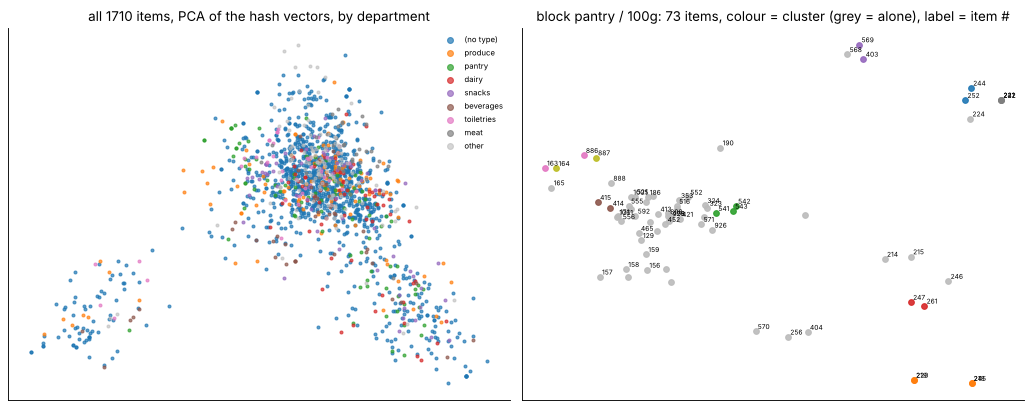

Item numbers in the right panel (first 12 of block ('pantry', '100g')):


#,cluster,item
129,1222,ממרח שוקולד 750 ג' נוטלה
156,1245,חטיף שיבולת שועל שוקולד מריר קראנצי 210ג' ניטשר ואלי
157,1232,חטיף קראנצי גרנולה שיבולת שועל 210 ג' ניטשר ואלי
158,1239,חטיף שיבולת שועל עם סירופ מייפל 210 ג' ניטשר ואלי
159,1233,חטיפי שיבולת שועל מלאה במגוון טעמים 210 ג' ניטשר ואלי
163,1193,חמאת בוטנים קלאסי 454 ג' סקיפי
164,1201,חמאת בוטנים עם שברי בוטנים 454 ג' סקיפי
165,1240,חמאת בוטנים ללא סוכר 340 ג' סקיפי
171,1220,חרדל אמירקי 300 ג'
186,1219,פירורי לחם מזוהבים 800 ג' אלחסן


In [11]:
try:
    import umap  # optional; not part of the notebooks group

    projector = umap.UMAP(n_components=2, metric="cosine", random_state=SEED)
    PROJ_NAME = "UMAP"
except ImportError:
    projector = PCA(n_components=2, random_state=SEED)
    PROJ_NAME = "PCA"
P = projector.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
depts = [r.dept or "(no type)" for r in rows]
top_depts = [d for d, _ in Counter(depts).most_common(8)]
cmap = plt.get_cmap("tab10")
for k, d in enumerate(top_depts):
    sel = [i for i, x in enumerate(depts) if x == d]
    axes[0].scatter(P[sel, 0], P[sel, 1], s=7, color=cmap(k), alpha=0.7, label=d)
other = [i for i, x in enumerate(depts) if x not in top_depts]
axes[0].scatter(P[other, 0], P[other, 1], s=7, color="#bbbbbb", alpha=0.6, label="other")
axes[0].set_title(f"all {len(rows)} items, {PROJ_NAME} of the {EMB_LABEL} vectors, by department")
axes[0].legend(fontsize=7, markerscale=2, frameon=False)

# right panel: the largest typed block, coloured by cluster, labelled with item numbers
typed_blocks = Counter(r.block for r in rows if r.dept)
show_block = typed_blocks.most_common(1)[0][0] if typed_blocks else blocks.most_common(1)[0][0]
sel = [i for i, r in enumerate(rows) if r.block == show_block]
Pb = PCA(n_components=2, random_state=SEED).fit_transform(X[sel])  # PCA of this block alone
sizes_in_block = Counter(agg[i] for i in sel)
multi_ids = sorted(c for c, n in sizes_in_block.items() if n >= 2)
for k, i in enumerate(sel):
    grouped = sizes_in_block[agg[i]] >= 2
    axes[1].scatter(
        Pb[k, 0],
        Pb[k, 1],
        s=26,
        color=cmap(multi_ids.index(agg[i]) % 10) if grouped else "#bbbbbb",
        alpha=0.9,
    )
for k, i in enumerate(sel[:60]):
    axes[1].annotate(str(rows[i].n), Pb[k], fontsize=6, xytext=(2, 2), textcoords="offset points")
axes[1].set_title(
    f"block {show_block[0]} / {show_block[1]}: {len(sel)} items, colour = cluster (grey = alone), label = item #"
)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()
print(f"Item numbers in the right panel (first 12 of block {show_block}):")
Table(["#", "cluster", "item"], [[rows[i].n, agg[i], rows[i].src.raw_name] for i in sel[:12]])

## f. Evaluation against ground truth the repo already has

Three sources, from strongest to weakest:

1. **Same valid GS1 barcode across chains** (real items). Exact-level truth: a positive pair is
   two items of different chains with the same barcode. *Recall* is the share of those pairs that
   ended in one cluster (and, as a ceiling, in one block). *Precision* cannot be read off barcodes:
   two different barcodes can still be the same product at the "any brand" level (Tnuva and Strauss
   3% milk), so the notebook reports the barcode-based figure as a **lower bound**, and splits the
   in-cluster pairs with different barcodes into "critical conflict", "differs only in size or soft
   attributes" and "attributes agree" (plausible any-brand equivalents, not verified).
2. **The synthetic gold set** (`data/gold/gold_pairs.csv`, 857 items, **synthetic**). Two items are
   the same product at the *any brand* level when they carry an `exact` or `any_brand` label for the
   same canonical, and at the *close substitute* level when they share any non-`no_match`
   canonical. Precision and recall are over all item pairs of the labelled items. The canonical
   definitions (`data/gold/gold_catalog.yaml`) give the true critical attributes, so a wrong pair can
   be classified independently of the rule extractor.
3. **Silver labels**: real items the repo's rule pipeline serves (`match_items`, accepted without a
   review flag) and that `data/audit/machine_verdicts.csv` marks `correct`. Items mapped to the same
   canonical are the same product. This is a **machine audit by one reader, not a gold set**, and
   the items are the easy ones the pipeline already matches.

**Hard rules.** Each variant is also run with a *hard-rule split*: every cluster is cut into groups
of equal critical signature (product type plus the critical values of that type, an unknown value is
its own group, as the judge sends unknown to review rather than guessing). This is the judge's veto
applied after the embedding. For the real items it is checked with the same attributes it is built
from, so its zero conflicts are true by construction and only its recall cost is informative; on the
gold set the check uses the canonical definitions, which the rules never saw.

In [12]:
# ---- ground truth 1: valid barcodes shared across chains (real items)
def barcode_truth(rows_):
    by = defaultdict(list)
    for i, r in enumerate(rows_):
        if r.barcode:
            by[r.barcode].append(i)
    pos = [
        (i, j)
        for m in by.values()
        for i, j in combinations(m, 2)
        if rows_[i].src.chain_id != rows_[j].src.chain_id
    ]
    return pos


POS = barcode_truth(rows)
ceiling = sum(rows[i].block == rows[j].block for i, j in POS)
print(
    f"{len(POS)} cross-chain positive pairs from {len({rows[i].barcode for i, _ in POS})} barcodes; "
    f"{ceiling} of them are in the same block (the recall ceiling of blocking)"
)


def barcode_eval(labels):
    hit = sum(labels[i] == labels[j] for i, j in POS)
    lab_groups = defaultdict(list)
    for i, r in enumerate(rows):
        if r.barcode:
            lab_groups[labels[i]].append(i)
    same = diff_crit = diff_soft = diff_agree = 0
    for m in lab_groups.values():
        for i, j in combinations(m, 2):
            a, b = rows[i], rows[j]
            if a.barcode == b.barcode:
                if a.src.chain_id != b.src.chain_id:
                    same += 1
                continue
            diffs, crit = pair_diffs(a, b)
            if crit:
                diff_crit += 1
            elif diffs:
                diff_soft += 1
            else:
                diff_agree += 1
    total = same + diff_crit + diff_soft + diff_agree
    return {
        "recall": ratio(hit, len(POS)),
        "hit": hit,
        "precision_lower_bound": ratio(same, total),
        "same_barcode_pairs": same,
        "diff_barcode_critical": diff_crit,
        "diff_barcode_soft_only": diff_soft,
        "diff_barcode_agree": diff_agree,
    }


# ---- the hard-rule split (the judge's veto applied to a clustering)
def critical_signature(r, with_percent=False):
    sig = (r.attrs.product_type, tuple(r.attrs.value(k) for k in sorted(r.crit)))
    # optional extra rule, not in the repo: a stated percentage always separates, even when the
    # product type is unknown or says the percentage is soft ("ח. טרי 3%" is milk, but no rule knows)
    return (*sig, r.attrs.fat_pct) if with_percent else sig


def hard_rule_split(labels, rows_, with_percent=False):
    out = np.zeros(len(labels), dtype=int)
    ids = {}
    for i, lab in enumerate(labels):
        out[i] = ids.setdefault((lab, critical_signature(rows_[i], with_percent)), len(ids))
    return out


# ---- pairwise precision and recall against a partition of (some of) the items
def pairwise_prf(pred, truth):
    idx = [i for i, t in enumerate(truth) if t is not None]
    pc = Counter(pred[i] for i in idx)
    tc = Counter(truth[i] for i in idx)
    both = Counter((pred[i], truth[i]) for i in idx)
    tp = sum(n_pairs(v) for v in both.values())
    predicted = sum(n_pairs(v) for v in pc.values())
    true = sum(n_pairs(v) for v in tc.values())
    return {
        "items": len(idx),
        "tp": tp,
        "predicted_pairs": predicted,
        "true_pairs": true,
        "precision": ratio(tp, predicted),
        "recall": ratio(tp, true),
    }

56 cross-chain positive pairs from 54 barcodes; 45 of them are in the same block (the recall ceiling of blocking)


In [13]:
# What the barcode positives say about blocking and about the rules (independent of any clustering)
apart = [(i, j) for i, j in POS if rows[i].block != rows[j].block]
true_conflict = [(i, j) for i, j in POS if pair_diffs(rows[i], rows[j])[1]]
unknown_only = [
    (i, j)
    for i, j in POS
    if not pair_diffs(rows[i], rows[j])[1]
    and critical_signature(rows[i]) != critical_signature(rows[j])
]
print(
    f"Of the {len(POS)} same-barcode pairs: {len(apart)} are separated by blocking alone "
    f"(different department or base unit, usually because one name is cut or states no type); "
    f"{len(true_conflict)} carry a conflict between two known values (the rules would veto a true match: "
    f"an extractor error or a chain data problem); {len(unknown_only)} differ only because one side "
    "is unknown (the strict split keeps unknown apart, the judge would send it to review)."
)
RESULTS["barcode_positives_apart_by_blocking"] = len(apart)
RESULTS["barcode_positives_true_conflict"] = len(true_conflict)
RESULTS["barcode_positives_unknown_only"] = len(unknown_only)
show = [("blocking", p) for p in apart[:5]] + [("known conflict", p) for p in true_conflict[:5]]
Table(
    ["why separated", "differs in", "block A", "block B", "item A", "item B"],
    [
        [
            why,
            ", ".join(pair_diffs(rows[i], rows[j])[1]),
            "/".join(rows[i].block),
            "/".join(rows[j].block),
            rows[i].src.raw_name,
            rows[j].src.raw_name,
        ]
        for why, (i, j) in show
    ],
)

Of the 56 same-barcode pairs: 11 are separated by blocking alone (different department or base unit, usually because one name is cut or states no type); 5 carry a conflict between two known values (the rules would veto a true match: an extractor error or a chain data problem); 4 differ only because one side is unknown (the strict split keeps unknown apart, the judge would send it to review).


why separated,differs in,block A,block B,item A,item B
blocking,,?/100g,?/?,מארז סבון מוצק פלמול,פלמוליב סבון מוצק יר
blocking,,?/100g,?/?,מארז סבון מוצק פלמול,פלמוליב סבון מוצק יר
blocking,,?/?,?/100ml,תרסיס מקסימה למייבש,סנו מקסימה פיור לאב
blocking,,?/?,?/100g,אריסה מרוקאית תבליני,אריסה חריף פיקנטי בי
blocking,,?/?,?/100g,חטיף פרוטאין מקס סופ,פרוטאין מקס חטיף סופ
known conflict,flavor,snacks/100g,snacks/100g,שוק.מריר לינדט 70% 100ג,לינדט אקסלנס שוקולד
known conflict,flavor,snacks/100g,snacks/100g,שוק.מריר לינדט 85% 100ג,לינדט אקסלנס שוקולד
known conflict,flavor,snacks/100g,snacks/100g,שוקולד מריר לינדט מלח 10,לינדט אקסלנס שוקולד
known conflict,flavor,snacks/100g,snacks/100g,שוק.מריר לינדט 90% 100ג,לינדט אקסלנס שוקולד
known conflict,flavor,snacks/100g,snacks/100g,לינדט אקסלנס שוקולד,שוק.מריר לינדט מנטה 100ג


In [14]:
# ---- ground truth 2: the synthetic gold set
import csv

import yaml

from smartcart_catalog.review_packet import GOLD_DIR, load_gold_items

gold_items = load_gold_items()
with (GOLD_DIR / "gold_pairs.csv").open(encoding="utf-8", newline="") as fh:
    gold_pairs = list(csv.DictReader(fh))
gold_canon = {
    c["slug"]: c
    for c in yaml.safe_load((GOLD_DIR / "gold_catalog.yaml").read_text(encoding="utf-8"))[
        "canonicals"
    ]
}
LEVEL_RANK = {"exact": 0, "any_brand": 1, "close": 2}
best = {}
for p in gold_pairs:
    if p["label"] in LEVEL_RANK:
        cur = best.get(p["item_key"])
        if cur is None or LEVEL_RANK[p["label"]] < LEVEL_RANK[cur[0]]:
            best[p["item_key"]] = (p["label"], p["canonical_slug"])
if SAMPLE and SAMPLE < len(gold_items):
    gold_items = subsample(gold_items, SAMPLE)
gold_rows = prepare(gold_items)
GOLD_KEYS = [it.key.removeprefix("gold:") for it in gold_items]
TRUTH_ANY = [
    best[k][1] if k in best and best[k][0] in ("exact", "any_brand") else None for k in GOLD_KEYS
]
TRUTH_CLOSE = [best[k][1] if k in best else None for k in GOLD_KEYS]
XG = embed_texts([r.text for r in gold_rows])
print(
    f"gold items: {len(gold_rows)}; with an any-brand canonical: {sum(t is not None for t in TRUTH_ANY)}; "
    f"with any positive canonical: {sum(t is not None for t in TRUTH_CLOSE)} (synthetic data)"
)


def canon_diff(x, y):
    """Which defining attributes differ between two gold canonicals."""
    cx, cy = gold_canon[x], gold_canon[y]
    tags = []
    if cx["product_type"] != cy["product_type"]:
        tags.append("product_type")
    ax, ay = cx.get("critical_attrs") or {}, cy.get("critical_attrs") or {}
    tags += [k for k in sorted(set(ax) | set(ay)) if ax.get(k) != ay.get(k)]
    return tags


def gold_eval(labels):
    any_ = pairwise_prf(labels, TRUTH_ANY)
    close = pairwise_prf(labels, TRUTH_CLOSE)
    # pairs together although their canonicals differ: which attribute makes them different?
    wrong = Counter()
    crit_wrong = soft_wrong = 0
    examples = []
    for m in members_of(labels).values():
        for i, j in combinations(m, 2):
            x, y = TRUTH_CLOSE[i], TRUTH_CLOSE[j]
            if x is None or y is None or x == y:
                continue
            tags = canon_diff(x, y)
            if tags:
                crit_wrong += 1
                wrong.update(tags)
                if len(examples) < 400:
                    examples.append((i, j, tags))
            else:
                soft_wrong += 1
    return {
        "any_brand": any_,
        "close": close,
        "wrong_pairs_critical": crit_wrong,
        "wrong_pairs_soft_only": soft_wrong,
        "wrong_by_attr": wrong,
        "examples": examples,
    }

gold items: 857; with an any-brand canonical: 672; with any positive canonical: 833 (synthetic data)


In [15]:
# ---- ground truth 3: silver labels from the repo's own rule pipeline + the machine audit
from smartcart_catalog.audit_real import load_verdicts
from smartcart_catalog.review_packet import match_items

verdicts = load_verdicts()
t0 = time.perf_counter()
matches = match_items(CATALOG, [r.src for r in rows])
SILVER = []
for m in matches:
    v = verdicts.get((m.item.key, m.canonical_slug or ""))
    served = m.canonical_slug is not None and not m.needs_review
    SILVER.append(m.canonical_slug if served and v is not None and v.verdict == "correct" else None)
print(
    f"rule pipeline over {len(rows)} real items in {time.perf_counter() - t0:.1f} s: "
    f"{sum(m.canonical_slug is not None for m in matches)} mapped, "
    f"{sum(m.canonical_slug is not None and not m.needs_review for m in matches)} served, "
    f"{sum(s is not None for s in SILVER)} served and marked correct by the machine audit "
    f"({len({s for s in SILVER if s})} canonicals)"
)

rule pipeline over 1710 real items in 3.9 s: 320 mapped, 103 served, 84 served and marked correct by the machine audit (60 canonicals)


In [16]:
VARIANTS = {}
RULES = {False: "", True: " + hard rules", "pct": " + hard rules + stated %"}
for method, lab in LABELS.items():
    gold_base = (
        cluster(XG, gold_rows, "agglomerative", THRESHOLD)
        if method == "agglomerative"
        else cluster(XG, gold_rows, "hdbscan")
    )
    for rules_on in RULES if method == "agglomerative" else (False, True):
        pct_rule = rules_on == "pct"
        real_lab, gold_lab = lab, gold_base
        if rules_on:
            real_lab = hard_rule_split(lab, rows, pct_rule)
            gold_lab = hard_rule_split(gold_base, gold_rows, pct_rule)
        VARIANTS[(method, rules_on)] = {
            "real": cluster_stats(real_lab, rows),
            "barcode": barcode_eval(real_lab),
            "silver": pairwise_prf(real_lab, SILVER),
            "gold": gold_eval(gold_lab),
            "real_labels": real_lab,
            "gold_labels": gold_lab,
        }


def vname(method, rules_on):
    return method + RULES[rules_on]


print(f"REAL ITEMS ({len(rows)}), embedder {EMB_LABEL}. Clusters are inside blocks.")
real_table = []
for key, v in VARIANTS.items():
    st, bc = v["real"], v["barcode"]
    real_table.append(
        [
            vname(*key),
            st["clusters"],
            st["pairs"],
            f"{st['crit_pairs']} ({pct(ratio(st['crit_pairs'], st['pairs']))})",
            f"{bc['hit']}/{len(POS)} ({pct(bc['recall'])})",
            f"{pct(bc['precision_lower_bound'])}",
            f"{bc['diff_barcode_critical']} / {bc['diff_barcode_soft_only']} / {bc['diff_barcode_agree']}",
        ]
    )
Table(
    [
        "variant",
        "clusters",
        "pairs in clusters",
        "critical-conflict pairs",
        "barcode recall",
        "barcode precision (lower bound)",
        "other-barcode pairs: critical / size-soft / agree",
    ],
    real_table,
)

REAL ITEMS (1710), embedder hash. Clusters are inside blocks.


variant,clusters,pairs in clusters,critical-conflict pairs,barcode recall,barcode precision (lower bound),other-barcode pairs: critical / size-soft / agree
agglomerative,1449,399,10 (2.5%),7/56 (12.5%),2.8%,8 / 40 / 191
agglomerative + hard rules,1461,386,0 (0.0%),7/56 (12.5%),3.0%,0 / 38 / 191
agglomerative + hard rules + stated %,1461,386,0 (0.0%),7/56 (12.5%),3.0%,0 / 38 / 191
hdbscan,943,1364,125 (9.2%),21/56 (37.5%),2.8%,82 / 217 / 442
hdbscan + hard rules,1027,1188,0 (0.0%),21/56 (37.5%),3.2%,0 / 208 / 432


In [17]:
print(
    f"SILVER LABELS (real items the rule pipeline serves and the machine audit marks correct), embedder {EMB_LABEL}"
)
silver_table = []
for key, v in VARIANTS.items():
    s = v["silver"]
    silver_table.append(
        [
            vname(*key),
            s["items"],
            s["true_pairs"],
            s["predicted_pairs"],
            s["tp"],
            fmt(s["precision"]),
            fmt(s["recall"]),
        ]
    )
display(
    Table(
        [
            "variant",
            "items",
            "true pairs",
            "predicted pairs",
            "correct pairs",
            "precision",
            "recall",
        ],
        silver_table,
    )
)

print(
    f"SYNTHETIC GOLD SET ({len(gold_rows)} items), embedder {EMB_LABEL}. Pairwise precision and recall."
)
gold_table = []
for key, v in VARIANTS.items():
    g = v["gold"]
    wrong = g["wrong_pairs_critical"] + g["wrong_pairs_soft_only"]
    gold_table.append(
        [
            vname(*key),
            f"{fmt(g['any_brand']['precision'])} / {fmt(g['any_brand']['recall'])}",
            f"{fmt(g['close']['precision'])} / {fmt(g['close']['recall'])}",
            f"{g['wrong_pairs_critical']} ({pct(ratio(g['wrong_pairs_critical'], g['close']['predicted_pairs']))})",
            g["wrong_pairs_soft_only"],
            ", ".join(f"{k} {n}" for k, n in g["wrong_by_attr"].most_common()) or "none",
        ]
    )
Table(
    [
        "variant",
        "any brand: precision / recall",
        "close substitute: precision / recall",
        "wrong pairs differing in a critical attribute (share of clustered pairs)",
        "wrong pairs differing only in soft attributes",
        "critical attribute that differs",
    ],
    gold_table,
)

SILVER LABELS (real items the rule pipeline serves and the machine audit marks correct), embedder hash


variant,items,true pairs,predicted pairs,correct pairs,precision,recall
agglomerative,84,54,19,16,0.842,0.296
agglomerative + hard rules,84,54,16,16,1.000,0.296
agglomerative + hard rules + stated %,84,54,16,16,1.000,0.296
hdbscan,84,54,35,15,0.429,0.278
hdbscan + hard rules,84,54,15,15,1.000,0.278


SYNTHETIC GOLD SET (857 items), embedder hash. Pairwise precision and recall.


variant,any brand: precision / recall,close substitute: precision / recall,wrong pairs differing in a critical attribute (share of clustered pairs),wrong pairs differing only in soft attributes,critical attribute that differs
agglomerative,0.736 / 0.182,0.750 / 0.171,309 (22.3%),38,"fat_pct 202, product_type 45, flavor 44, state 18, base 11"
agglomerative + hard rules,0.944 / 0.176,0.955 / 0.166,10 (0.9%),38,"fat_pct 4, product_type 4, flavor 2"
agglomerative + hard rules + stated %,0.946 / 0.175,0.958 / 0.165,6 (0.6%),38,"product_type 4, flavor 2"
hdbscan,0.878 / 0.101,0.874 / 0.097,85 (12.6%),0,"fat_pct 41, product_type 21, state 15, base 13"
hdbscan + hard rules,0.993 / 0.098,0.991 / 0.095,5 (0.9%),0,fat_pct 5


In [18]:
# the pairs behind the numbers: real in-cluster pairs with a critical conflict, embedding only
base = VARIANTS[("agglomerative", False)]
lab = base["real_labels"]
conflict_pairs = []
for m in members_of(lab).values():
    for i, j in combinations(m, 2):
        diffs, crit = pair_diffs(rows[i], rows[j])
        if crit:
            conflict_pairs.append((float(X[i] @ X[j]), i, j, crit))
# fat percentage first (the example the project names), then the rest, most similar first
conflict_pairs.sort(key=lambda t: ("fat_pct" not in t[3], -t[0]))
print(
    f"{len(conflict_pairs)} real in-cluster pairs with a critical conflict (embedder {EMB_LABEL}, "
    f"agglomerative, no hard rules); the first 10, fat percentage first:"
)
Table(
    ["cosine", "differs in", "item A", "item B"],
    [
        [f"{s:.3f}", ", ".join(c), rows[i].src.raw_name, rows[j].src.raw_name]
        for s, i, j, c in conflict_pairs[:10]
    ],
)

10 real in-cluster pairs with a critical conflict (embedder hash, agglomerative, no hard rules); the first 10, fat percentage first:


cosine,differs in,item A,item B
0.944,product_type,"משקה מוגז בטעם קולה 150 מ""ל צ'אט","משקה מוגז בטעם קולה זירו 150 מ""ל צ'אט"
0.884,product_type,"טבסקו פלפל אדום 60 מ""ל","טבסקו פלפל שום 60 מ""ל"
0.861,product_type,"משקה אנרגיה אבטיח 250 מ""ל רד בול","משקה אנרגיה ענבים 250 מ""ל רד בול"
0.778,product_type,כרעיים עוף טרי עטרה,כנפיים עוף טרי עטרה
0.763,flavor,גבינת שמנת טבעי 25%,גבינת שמנת זיתים 25%
0.763,product_type,חזה עוף קפוא מחפוד,שניצל עוף מחפוד קפוא
0.761,product_type,נקטר ספרינג מנגו 1 ל,נקטר ספרינג תפוז 1 ל
0.758,product_type,שוקיים עוף טרי עטרה,כנפיים עוף טרי עטרה
0.756,product_type,קולה 2 ליטר בודד,קולה זירו 2 ליטר בוד
0.755,product_type,כרעיים עוף טרי עטרה,שוקיים עוף טרי עטרה


In [19]:
g = VARIANTS[("agglomerative", False)]["gold"]
gold_ex = sorted(
    g["examples"],
    key=lambda t: (
        "fat_pct" not in t[2],
        -float(XG[t[0]] @ XG[t[1]]),
    ),
)[:10]
print(
    f"gold pairs clustered together although their canonicals differ in a critical attribute "
    f"(embedder {EMB_LABEL}, agglomerative, no hard rules); {g['wrong_pairs_critical']} in total, the first 10:"
)
Table(
    ["cosine", "canonicals differ in", "item A", "item B"],
    [
        [
            f"{float(XG[i] @ XG[j]):.3f}",
            ", ".join(tags),
            gold_rows[i].src.raw_name,
            gold_rows[j].src.raw_name,
        ]
        for i, j, tags in gold_ex
    ],
)

gold pairs clustered together although their canonicals differ in a critical attribute (embedder hash, agglomerative, no hard rules); 309 in total, the first 10:


cosine,canonicals differ in,item A,item B
0.940,fat_pct,גבינה צהובה פרוסה 28% תנובה 200 גרם,גבינה צהובה פרוסה 9% תנובה 200 גרם
0.940,fat_pct,גבינה צהובה פרוסה 28% מחלבות גד 200 גרם,גבינה צהובה פרוסה 9% מחלבות גד 200 גרם
0.937,fat_pct,גבינה צהובה פרוסה 28% רמי לוי 200 גרם,גבינה צהובה פרוסה 9% רמי לוי 200 גרם
0.935,fat_pct,גבינה צהובה פרוסה 28% שופרסל 200 גרם,גבינה צהובה פרוסה 9% שופרסל 200 גרם
0.924,fat_pct,רמי לוי גבינה לבנה 5% 500 גרם,גבינה לבנה 9% רמי לוי 500 גרם
0.923,fat_pct,רמי לוי גבינה צהובה 28% 200 גרם,רמי לוי גבינה צהובה 9% 200 גרם
0.923,fat_pct,גבינה צהובה 28% 200 גרם רמי לוי,רמי לוי גבינה צהובה 9% 200 גרם
0.919,fat_pct,מחלבות גד גבינה לבנה 5% 250 גרם,גבינה לבנה 9% מחלבות גד 250 גרם
0.919,fat_pct,מחלבות גד גבינה לבנה 5% 250 גרם,מחלבות גד גבינה לבנה 9% 250 גרם
0.918,fat_pct,רמי לוי גבינה לבנה 5% 250 גרם,גבינה לבנה 9% רמי לוי 250 גרם


In [20]:
# what the hard rules still miss: gold pairs together although their canonicals differ in a
# critical attribute, after the hard-rule split (the extractor read both sides as the same or unknown)
gr = VARIANTS[("agglomerative", True)]["gold"]
residual = sorted(gr["examples"], key=lambda t: -float(XG[t[0]] @ XG[t[1]]))[:10]
print(
    f"{gr['wrong_pairs_critical']} gold pairs remain after the hard rules (embedder {EMB_LABEL}, "
    "agglomerative); the 10 most similar:"
)
Table(
    ["cosine", "canonicals differ in", "item A", "item B", "rule view of A", "rule view of B"],
    [
        [
            f"{float(XG[i] @ XG[j]):.3f}",
            ", ".join(tags),
            gold_rows[i].src.raw_name,
            gold_rows[j].src.raw_name,
            f"{gold_rows[i].attrs.product_type} / fat {gold_rows[i].attrs.fat_pct}",
            f"{gold_rows[j].attrs.product_type} / fat {gold_rows[j].attrs.fat_pct}",
        ]
        for i, j, tags in residual
    ],
)

10 gold pairs remain after the hard rules (embedder hash, agglomerative); the 10 most similar:


cosine,canonicals differ in,item A,item B,rule view of A,rule view of B
0.897,fat_pct,ח. טרי 3% 1 ל' ויקטורי,ח. טרי 1% 1 ליטר ויקטורי,None / fat 3,None / fat 1
0.891,product_type,פפסי 6*1.5 ל',פפסי מקס 6*1.5 ל',None / fat None,None / fat None
0.883,fat_pct,ח. טרי 3% 1 ליטר טרה,ח. טרי 1% 1 ליטר טרה,None / fat 3,None / fat 1
0.874,product_type,פפסי 1.5 ליטר,פפסי מקס 1.5 ליטר,None / fat None,None / fat None
0.870,fat_pct,תנובה יוגורט תות 3% 200 גרם,יוגורט תות 1.5% תנובה 200 גרם,yogurt_fruit / fat 3,yogurt_fruit / fat 1.5
0.837,flavor,"סוכר לבן וילי פוד 1 ק""ג","סוכר דמררה וילי פוד 1 ק""ג",sugar_white / fat None,sugar_white / fat None
0.817,product_type,פפסי 1.5 ליטר,פפסי מקס 6*1.5 ל',None / fat None,None / fat None
0.807,fat_pct,ח. טרי 3% 1 ל' יוחננוף,ח. טרי 1% 2 ל' יוחננוף,None / fat 3,None / fat 1
0.804,product_type,פפסי 6*1.5 ל',פפסי מקס 1.5 ליטר,None / fat None,None / fat None
0.771,flavor,"וילי פוד סוכר לבן מזוקק 1 ק""ג","סוכר דמררה וילי פוד 1 ק""ג",sugar_white / fat None,sugar_white / fat None


In [21]:
# the same numbers over the whole threshold grid, so the chosen threshold is not the only view
def f_beta(p, r, beta=0.5):
    if not p or not r:
        return 0.0
    return (1 + beta**2) * p * r / (beta**2 * p + r)


sens = []
for thr in GRID:
    rl = cluster(X, rows, "agglomerative", thr)
    gl = cluster(XG, gold_rows, "agglomerative", thr)
    rl2, gl2 = hard_rule_split(rl, rows), hard_rule_split(gl, gold_rows)
    st, be, be2 = cluster_stats(rl, rows), barcode_eval(rl), barcode_eval(rl2)
    g1, g2 = pairwise_prf(gl, TRUTH_ANY), pairwise_prf(gl2, TRUTH_ANY)
    sens.append(
        {
            "thr": thr,
            "crit": ratio(st["crit_pairs"], st["pairs"]),
            "bc": be["recall"],
            "bc_rules": be2["recall"],
            "g": g1,
            "g_rules": g2,
            "f05": f_beta(g2["precision"], g2["recall"]),
        }
    )
BEST = max(sens, key=lambda d: (d["f05"], -d["thr"]))
print(
    f"threshold sensitivity, embedder {EMB_LABEL} (agglomerative). <- the threshold used above; "
    "* the best F0.5 of gold any-brand pairs after the hard rules (precision counts four times "
    "as much as recall in F0.5; this uses the synthetic gold set, nothing else was tuned on it)"
)
Table(
    [
        "distance threshold",
        "real: critical-conflict pairs",
        "real: barcode recall",
        "real: barcode recall, hard rules",
        "gold any brand: precision / recall",
        "gold any brand, hard rules: precision / recall",
    ],
    [
        [
            f"{d['thr']:.2f}"
            + (" <-" if d["thr"] == THRESHOLD else "")
            + (" *" if d is BEST else ""),
            pct(d["crit"]),
            pct(d["bc"]),
            pct(d["bc_rules"]),
            f"{fmt(d['g']['precision'])} / {fmt(d['g']['recall'])}",
            f"{fmt(d['g_rules']['precision'])} / {fmt(d['g_rules']['recall'])}",
        ]
        for d in sens
    ],
)

threshold sensitivity, embedder hash (agglomerative). <- the threshold used above; * the best F0.5 of gold any-brand pairs after the hard rules (precision counts four times as much as recall in F0.5; this uses the synthetic gold set, nothing else was tuned on it)


distance threshold,real: critical-conflict pairs,real: barcode recall,"real: barcode recall, hard rules",gold any brand: precision / recall,"gold any brand, hard rules: precision / recall"
0.10,0.6%,3.6%,3.6%,0.966 / 0.048,1.000 / 0.047
0.15,1.3%,10.7%,10.7%,0.849 / 0.079,0.994 / 0.077
0.20,1.0%,10.7%,10.7%,0.801 / 0.126,0.971 / 0.122
0.25 <-,2.5%,12.5%,12.5%,0.736 / 0.182,0.944 / 0.176
0.30,5.2%,17.9%,17.9%,0.707 / 0.256,0.955 / 0.249
0.35,4.9%,23.2%,23.2%,0.647 / 0.369,0.954 / 0.357
0.40,4.9%,28.6%,28.6%,0.636 / 0.471,0.960 / 0.451
0.45,4.8%,35.7%,35.7%,0.586 / 0.657,0.957 / 0.629
0.50,4.7%,46.4%,46.4%,0.508 / 0.772,0.910 / 0.736
0.55,5.3%,48.2%,48.2%,0.452 / 0.802,0.902 / 0.765


## g. Conclusions

The first cell below is generated from the numbers computed above, so it always describes the run
that produced the outputs. The second cell is the reading that holds for any embedder.

In [22]:
A, AR = VARIANTS[("agglomerative", False)], VARIANTS[("agglomerative", True)]
AP = VARIANTS[("agglomerative", "pct")]
n_ceiling = ceiling
lines = [
    f"**Run:** embedder `{EMB_LABEL}` ({EMB_STATUS}), {len(rows)} real items, {len(gold_rows)} synthetic gold items, "
    f"agglomerative distance threshold {THRESHOLD}. All numbers below are *measured* by this notebook.",
    "",
    f"* **Real items, clusters.** {A['real']['clusters']} clusters; {A['real']['singletons']} singletons; "
    f"largest {A['real']['largest']}; {A['real']['pairs']} pairs inside clusters.",
    f"* **Barcode truth (exact level).** {A['barcode']['hit']} of {len(POS)} cross-chain same-barcode pairs end in one cluster "
    f"(recall {pct(A['barcode']['recall'])}); blocking alone already separates {len(POS) - n_ceiling} of them, "
    f"so {pct(ratio(n_ceiling, len(POS)))} is the ceiling.",
    f"* **Critical conflicts on real items.** {pct(ratio(A['real']['crit_pairs'], A['real']['pairs']))} of the pairs inside "
    f"clusters ({A['real']['crit_pairs']}) differ in a critical attribute the rules can read; with the hard-rule split "
    f"0 by construction, and barcode recall goes from {pct(A['barcode']['recall'])} to {pct(AR['barcode']['recall'])}. "
    f"Among all {len(POS)} true same-barcode pairs, {len(true_conflict)} carry a conflict between known values "
    f"(rule false alarms or chain data problems) and {len(unknown_only)} differ only by an unknown value.",
    f"* **Gold set, any brand.** embedding only: precision {fmt(A['gold']['any_brand']['precision'])}, recall "
    f"{fmt(A['gold']['any_brand']['recall'])}; with hard rules: precision {fmt(AR['gold']['any_brand']['precision'])}, recall "
    f"{fmt(AR['gold']['any_brand']['recall'])}. Without the rules {A['gold']['wrong_pairs_critical']} clustered pairs differ in a "
    f"critical attribute ({pct(ratio(A['gold']['wrong_pairs_critical'], A['gold']['close']['predicted_pairs']))} of the "
    f"clustered pairs); with them {AR['gold']['wrong_pairs_critical']}. One extra rule (a stated percentage always "
    f"separates, which the repo's rules do not do for names with no product type) gives precision "
    f"{fmt(AP['gold']['any_brand']['precision'])}, recall {fmt(AP['gold']['any_brand']['recall'])} and "
    f"{AP['gold']['wrong_pairs_critical']} such pairs.",
    f"* **Silver labels.** precision {fmt(A['silver']['precision'])} and recall {fmt(A['silver']['recall'])} on "
    f"{A['silver']['items']} items (machine audit, easy items).",
]
lines.append(
    f"* **Why rules.** Section d: the most similar must-not-merge pair scores {RESULTS['must_not_merge_cosine_max']}, the "
    f"least similar same-product pair {RESULTS['same_product_cosine_min']} (median of random item pairs "
    f"{np.median(random_cos):.3f}). Where the first number is not clearly below the second, similarity cannot separate them."
)
lines.append(
    f"* **A recall-oriented point.** At distance {BEST['thr']:.2f} (best F0.5 on the gold set with hard rules): gold any-brand "
    f"precision {fmt(BEST['g_rules']['precision'])} and recall {fmt(BEST['g_rules']['recall'])} with the rules "
    f"({fmt(BEST['g']['precision'])} / {fmt(BEST['g']['recall'])} without); real barcode recall "
    f"{pct(BEST['bc'])} without and {pct(BEST['bc_rules'])} with the rules, "
    f"{pct(BEST['crit'])} of the real in-cluster pairs conflict before the rules."
)
display(Markdown("\n".join(lines)))

RESULTS.update(
    embedder=EMB_LABEL,
    model=embedder.model_name,
    status=EMB_STATUS,
    real_items=len(rows),
    gold_items=len(gold_rows),
    threshold=THRESHOLD,
    clusters=A["real"]["clusters"],
    pairs_in_clusters=A["real"]["pairs"],
    critical_conflict_pairs=A["real"]["crit_pairs"],
    barcode_positives=len(POS),
    barcode_recall=A["barcode"]["recall"],
    barcode_recall_hard_rules=AR["barcode"]["recall"],
    gold_any_brand_precision=A["gold"]["any_brand"]["precision"],
    gold_any_brand_recall=A["gold"]["any_brand"]["recall"],
    gold_any_brand_precision_hard_rules=AR["gold"]["any_brand"]["precision"],
    gold_any_brand_recall_hard_rules=AR["gold"]["any_brand"]["recall"],
    gold_critical_wrong_pairs=A["gold"]["wrong_pairs_critical"],
    gold_critical_wrong_pairs_hard_rules=AR["gold"]["wrong_pairs_critical"],
    gold_any_brand_precision_hard_rules_pct=AP["gold"]["any_brand"]["precision"],
    gold_any_brand_recall_hard_rules_pct=AP["gold"]["any_brand"]["recall"],
    gold_critical_wrong_pairs_hard_rules_pct=AP["gold"]["wrong_pairs_critical"],
    best_f05_threshold=BEST["thr"],
    best_f05_gold_precision_hard_rules=BEST["g_rules"]["precision"],
    best_f05_gold_recall_hard_rules=BEST["g_rules"]["recall"],
    best_f05_barcode_recall=BEST["bc"],
    best_f05_barcode_recall_hard_rules=BEST["bc_rules"],
    best_f05_real_conflict_share=BEST["crit"],
    silver_precision=A["silver"]["precision"],
    silver_recall=A["silver"]["recall"],
)

**Run:** embedder `hash` (offline, deterministic), 1710 real items, 857 synthetic gold items, agglomerative distance threshold 0.25. All numbers below are *measured* by this notebook.

* **Real items, clusters.** 1449 clusters; 1262 singletons; largest 7; 399 pairs inside clusters.
* **Barcode truth (exact level).** 7 of 56 cross-chain same-barcode pairs end in one cluster (recall 12.5%); blocking alone already separates 11 of them, so 80.4% is the ceiling.
* **Critical conflicts on real items.** 2.5% of the pairs inside clusters (10) differ in a critical attribute the rules can read; with the hard-rule split 0 by construction, and barcode recall goes from 12.5% to 12.5%. Among all 56 true same-barcode pairs, 5 carry a conflict between known values (rule false alarms or chain data problems) and 4 differ only by an unknown value.
* **Gold set, any brand.** embedding only: precision 0.736, recall 0.182; with hard rules: precision 0.944, recall 0.176. Without the rules 309 clustered pairs differ in a critical attribute (22.3% of the clustered pairs); with them 10. One extra rule (a stated percentage always separates, which the repo's rules do not do for names with no product type) gives precision 0.946, recall 0.175 and 6 such pairs.
* **Silver labels.** precision 0.842 and recall 0.296 on 84 items (machine audit, easy items).
* **Why rules.** Section d: the most similar must-not-merge pair scores 0.859, the least similar same-product pair 0.644 (median of random item pairs 0.043). Where the first number is not clearly below the second, similarity cannot separate them.
* **A recall-oriented point.** At distance 0.80 (best F0.5 on the gold set with hard rules): gold any-brand precision 0.896 and recall 0.810 with the rules (0.187 / 0.848 without); real barcode recall 75.0% without and 66.1% with the rules, 9.1% of the real in-cluster pairs conflict before the rules.

**How to read it (the same for every embedder).**

* Embeddings are a **candidate generator**. They find "same thing, different words" and they rank,
  but a cosine score has no notion of which difference matters: "חלב 3%" and "חלב 1%" differ in one
  character and sit next to each other in any lexical space, and even a semantic model will place
  them close because they are about the same thing. The section-d table shows the numbers.
* The **judge's hard rules decide** (`docs/matching.md`, step D, decision D5): product type and the
  critical attributes of that type are compared as values, never as similarity, and unknown means
  "review". The hard-rule rows above show the effect: critical conflicts go to zero, and what is
  paid is recall. That trade is the project's rule: *precision over recall*; one wrong 3%-for-1%
  match costs more trust than ten missed ones.
* **Blocking** is part of the precision story and also of the recall ceiling: an item whose name
  is cut before the product word lands in the block "?" and never meets its twin in a typed block.
  The recall figures are therefore lower than a cosine ranking alone would give.

**What is an estimate, not measured here.** Anything about BGE-M3 or e5 on these items (the notebook
can measure it; see `docs/matching.md`, "Exploration notebook" for the figures recorded so far);
that a better embedder moves the threshold the same way; precision on the real catalog (the gold set
is synthetic and the silver labels come from a machine audit); and the 98% target of the project
(D5 in `docs/decisions.md`), which needs the human-labelled gold set (issue #38).

In [23]:
RESULTS["runtime_seconds"] = round(time.perf_counter() - T_START, 1)
print("RESULTS " + json.dumps(RESULTS, ensure_ascii=False, sort_keys=True, default=str))

RESULTS {"barcode_positives": 56, "barcode_positives_apart_by_blocking": 11, "barcode_positives_true_conflict": 5, "barcode_positives_unknown_only": 4, "barcode_recall": 0.125, "barcode_recall_hard_rules": 0.125, "best_f05_barcode_recall": 0.75, "best_f05_barcode_recall_hard_rules": 0.6607142857142857, "best_f05_gold_precision_hard_rules": 0.8958051420838972, "best_f05_gold_recall_hard_rules": 0.8102815177478581, "best_f05_real_conflict_share": 0.09097578870139399, "best_f05_threshold": 0.8, "clusters": 1449, "critical_conflict_pairs": 10, "embedder": "hash", "gold_any_brand_precision": 0.736372646184341, "gold_any_brand_precision_hard_rules": 0.9435695538057742, "gold_any_brand_precision_hard_rules_pct": 0.9457671957671958, "gold_any_brand_recall": 0.18188494492044063, "gold_any_brand_recall_hard_rules": 0.17600979192166463, "gold_any_brand_recall_hard_rules_pct": 0.17503059975520197, "gold_critical_wrong_pairs": 309, "gold_critical_wrong_pairs_hard_rules": 10, "gold_critical_wrong_pa